> **Versi arsip ARIMAX-GARCH** (`arsip/arimax_garch/`, terpisah dari skripsi). Persamaan mean
> dimodelkan dulu dengan ARIMAX, lalu GARCH dipasang pada residual ARIMAX.

# 01 ARIMAX-GARCH

Notebook ini membangun model ARIMAX-GARCH untuk satu emiten:

1. **ARIMAX** pada log return saham, dengan variabel eksogen log return emas dan nikel (ANTM)
   atau nikel (INCO) **hari sebelumnya** ($x_{t-1}$). Orde dipilih dengan `auto_arima`
   stepwise, AIC terkecil.
2. **GARCH** pada residual ARIMAX dengan persamaan mean nol. Orde dan distribusi dipilih
   seperti di skripsi.
3. Kolom `sigma` pada sheet `conditional_volatility` menjadi fitur `garch_vol` untuk model
   hybrid di notebook 02.
4. **Peramalan ARIMAX-GARCH** pada 305 hari data testing, satu langkah ke depan.

Seluruh estimasi hanya memakai data training. Data testing dipakai dengan parameter yang
dibekukan: residual ARIMAX periode testing berasal dari ramalan satu langkah, dan
volatilitasnya dari rekursi GARCH satu langkah.

Kedua notebook 01 identik; yang berbeda hanya sel parameter di bawah.

In [1]:
EMITEN = "INCO"   # ANTM / INCO

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pmdarima as pm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy import stats
from arch import arch_model
from IPython.display import display

pd.set_option("display.max_colwidth", None)
os.makedirs("outputs", exist_ok=True)
BERKAS_XLSX = "outputs/01_arimax_garch_" + EMITEN + ".xlsx"
KOLOM = EMITEN.lower()
EKSOGEN = {"ANTM": ["emas", "nikel"], "INCO": ["nikel"]}[EMITEN]
ALPHA = 0.05                  # taraf signifikansi
LAG_ACF = 40
LAG_ARCH = [1, 10, 12, 20]
LAG_LJUNG_BOX = [10, 20]
tabel = {}   # seluruh tabel yang disimpan ke xlsx, sesuai urutan langkah

def tampil(df):
    # tampilkan 10 baris teratas dan 10 baris terbawah
    if len(df) <= 20:
        display(df)
    else:
        display(pd.concat([df.head(10), df.tail(10)]))

## 1. Data

Pembagian mengikuti skripsi (`metodologi.md` bagian 2): $n_{test} = round(1.523 \times 0{,}2) = 305$.
Periode testing adalah 305 hari terakhir (13 Januari 2025 sampai 30 April 2026).

In [3]:
data = pd.read_csv("data/data_" + KOLOM + ".csv")
data["Tanggal"] = pd.to_datetime(data["Tanggal"])
N_ASLI = len(data)
n_test = round(N_ASLI * 0.2)
assert N_ASLI == 1523 and n_test == 305 and data.isna().sum().sum() == 0
tabel["data"] = data
tampil(data)

,Tanggal,inco,nikel
0,2020-01-02,3620.0,14260.00
1,2020-01-03,3500.0,13755.00
2,2020-01-06,3530.0,13820.00
3,2020-01-07,3560.0,13935.00
4,2020-01-08,3540.0,14050.00
5,2020-01-09,3570.0,14085.00
6,2020-01-10,3510.0,14190.00
7,2020-01-13,3460.0,14095.00
8,2020-01-14,3420.0,13870.00
9,2020-01-15,3410.0,14320.00


## 2. Log return dan eksogen hari sebelumnya

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) \times 100$$

dihitung untuk harga saham dan setiap variabel eksogen. Log return eksogen lalu digeser satu
hari (kolom `*_lag1` = log return eksogen hari sebelumnya), sehingga ARIMAX untuk hari $t$
hanya memakai informasi sampai hari $t-1$, sama seperti LSTM dan GRU.

**Sebelum** baris kosong dibuang: hari ke-1 belum memiliki log return, dan hari ke-2 belum
memiliki log return eksogen hari sebelumnya.

In [4]:
log_return = data[["Tanggal", KOLOM]].copy()
log_return["r_" + KOLOM] = np.log(data[KOLOM] / data[KOLOM].shift(1)) * 100
for k in EKSOGEN:
    log_return["r_" + k + "_lag1"] = (np.log(data[k] / data[k].shift(1)) * 100).shift(1)
tabel["log_return_sebelum"] = log_return.copy()
tampil(log_return)

,Tanggal,inco,r_inco,r_nikel_lag1
0,2020-01-02,3620.0,NaN,NaN
1,2020-01-03,3500.0,-3.371106,NaN
2,2020-01-06,3530.0,0.853490,-3.605602
3,2020-01-07,3560.0,0.846267,0.471442
4,2020-01-08,3540.0,-0.563382,0.828684
5,2020-01-09,3570.0,0.843887,0.821873
6,2020-01-10,3510.0,-1.694956,0.248801
7,2020-01-13,3460.0,-1.434745,0.742709
8,2020-01-14,3420.0,-1.162804,-0.671737
9,2020-01-15,3410.0,-0.292826,-1.609189


**Sesudah** dua hari pertama dibuang (tanpa imputasi): deret dimulai 6 Januari 2020 dan
berisi 1.521 hari, yaitu 1.216 hari training dan 305 hari testing. Periode testing tidak
berubah.

In [5]:
sampel = log_return.dropna().reset_index(drop=True)
N = len(sampel)
n_train = N - n_test
assert N == 1521 and n_train == 1216
assert sampel["Tanggal"][n_train] == data["Tanggal"][N_ASLI - n_test]   # hari testing pertama sama
sampel["periode"] = ["training"] * n_train + ["testing"] * n_test
KOLOM_Y = "r_" + KOLOM
KOLOM_X = ["r_" + k + "_lag1" for k in EKSOGEN]
tabel["log_return_sesudah"] = sampel
tampil(sampel)

train = sampel.iloc[:n_train]

,Tanggal,inco,r_inco,r_nikel_lag1,periode
0,2020-01-06,3530.0,0.853490,-3.605602,training
1,2020-01-07,3560.0,0.846267,0.471442,training
2,2020-01-08,3540.0,-0.563382,0.828684,training
3,2020-01-09,3570.0,0.843887,0.821873,training
4,2020-01-10,3510.0,-1.694956,0.248801,training
5,2020-01-13,3460.0,-1.434745,0.742709,training
6,2020-01-14,3420.0,-1.162804,-0.671737,training
7,2020-01-15,3410.0,-0.292826,-1.609189,training
8,2020-01-16,3530.0,3.458558,3.192893,training
9,2020-01-17,3500.0,-0.853490,-3.880181,training


## 3. Plot log return, ACF, dan PACF

Plot log return memperlihatkan *volatility clustering*. ACF dan PACF (sampai lag 40)
dihitung pada harga (level) dan pada log return, seluruhnya pada 1.216 hari training.

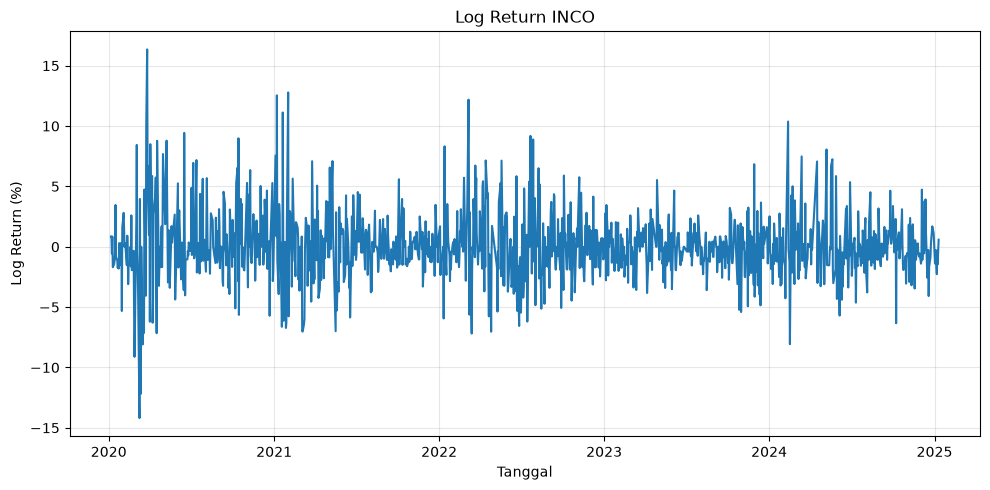

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train["Tanggal"], train[KOLOM_Y], color="tab:blue")
ax.set_title("Log Return " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Log Return (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/gambar_log_return_" + EMITEN + ".png", dpi=300)
plt.show()

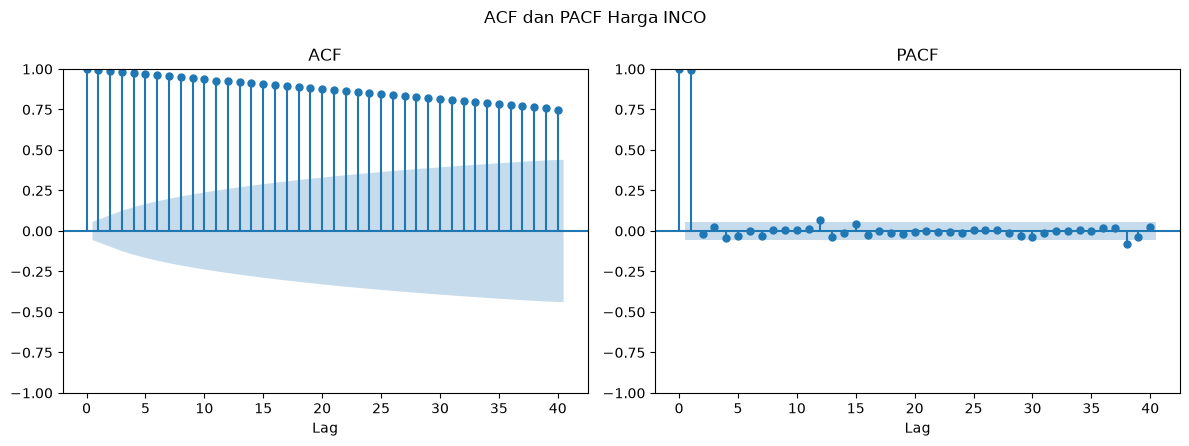

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_acf(train[KOLOM], lags=LAG_ACF, ax=ax[0], title="ACF")
plot_pacf(train[KOLOM], lags=LAG_ACF, ax=ax[1], title="PACF")
ax[0].set_xlabel("Lag")
ax[1].set_xlabel("Lag")
fig.suptitle("ACF dan PACF Harga " + EMITEN)
plt.tight_layout()
plt.savefig("outputs/gambar_acf_pacf_harga_" + EMITEN + ".png", dpi=300)
plt.show()

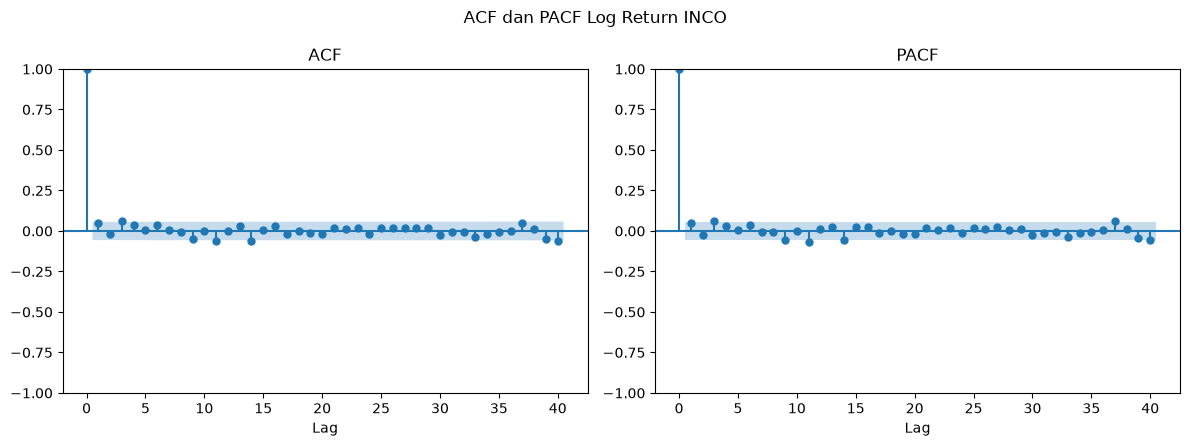

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_acf(train[KOLOM_Y], lags=LAG_ACF, ax=ax[0], title="ACF")
plot_pacf(train[KOLOM_Y], lags=LAG_ACF, ax=ax[1], title="PACF")
ax[0].set_xlabel("Lag")
ax[1].set_xlabel("Lag")
fig.suptitle("ACF dan PACF Log Return " + EMITEN)
plt.tight_layout()
plt.savefig("outputs/gambar_acf_pacf_log_return_" + EMITEN + ".png", dpi=300)
plt.show()

## 4. Uji ADF

$H_0$: deret memiliki akar unit (tidak stasioner). $H_0$ ditolak bila p-value < 0,05.
Jumlah lag dipilih otomatis dengan AIC. Diuji pada harga, log return saham, dan log return
eksogen hari sebelumnya (data training).

In [9]:
daftar_deret = [("harga", train[KOLOM]), ("log return", train[KOLOM_Y])]
daftar_deret += [("log return " + k + " (hari sebelumnya)", train["r_" + k + "_lag1"]) for k in EKSOGEN]
baris = []
for nama, deret in daftar_deret:
    hasil_adf = adfuller(deret, autolag="AIC")
    keputusan = "stasioner" if hasil_adf[1] < ALPHA else "tidak stasioner"
    baris.append([nama, hasil_adf[0], hasil_adf[1], hasil_adf[2], hasil_adf[3],
                  hasil_adf[4]["1%"], hasil_adf[4]["5%"], hasil_adf[4]["10%"], keputusan])
uji_adf = pd.DataFrame(baris, columns=["variabel", "statistik_adf", "p_value", "lag", "jumlah_observasi",
                                       "nilai_kritis_1%", "nilai_kritis_5%", "nilai_kritis_10%", "keputusan"])
tabel["uji_adf"] = uji_adf
display(uji_adf)

,variabel,statistik_adf,p_value,lag,jumlah_observasi,nilai_kritis_1%,nilai_kritis_5%,nilai_kritis_10%,keputusan
0,harga,-1.789386,3.857441e-01,3,1212,-3.435757,-2.863928,-2.568041,tidak stasioner
1,log return,-18.810100,2.022471e-30,2,1213,-3.435752,-2.863926,-2.568040,stasioner
2,log return nikel (hari sebelumnya),-10.497377,1.106516e-18,21,1194,-3.435839,-2.863964,-2.568060,stasioner


## 5. ARIMAX dengan auto ARIMA stepwise

`auto_arima` (pmdarima) dijalankan pada 1.216 hari training dengan pencarian bertahap
(*stepwise*): orde differencing $d$ ditentukan otomatis (uji KPSS, bawaan pmdarima), lalu $p$
dan $q$ dicari sampai 5, dengan dan tanpa intercept. Model dengan **AIC terkecil** dipilih.
Model yang dihasilkan adalah regresi dengan galat ARIMA:

$$r_t = \sum_{k} \beta_k\, x_{k,t-1} + u_t, \qquad u_t \sim \text{ARIMA}(p, d, q)$$

Tabel kandidat berisi seluruh model yang berhasil diestimasi selama pencarian, diurutkan
dari AIC terkecil.

In [10]:
kandidat = pm.auto_arima(train[KOLOM_Y], X=train[KOLOM_X], seasonal=False, stepwise=True,
                         information_criterion="aic", suppress_warnings=True, error_action="ignore",
                         return_valid_fits=True)
model_arimax = kandidat[0]   # kandidat pertama = model terpilih (AIC terkecil)
assert model_arimax.aic() == min(m.aic() for m in kandidat)

baris = []
for m in kandidat:
    p, d, q = m.order
    baris.append([p, d, q, "ya" if m.with_intercept else "tidak", m.aic()])
kandidat_arimax = pd.DataFrame(baris, columns=["p", "d", "q", "intercept", "aic"])
tabel["kandidat_arimax"] = kandidat_arimax
tampil(kandidat_arimax)

p, d, q = model_arimax.order
orde_arimax = pd.DataFrame([[p, d, q, "ya" if model_arimax.with_intercept else "tidak",
                             model_arimax.aic(), model_arimax.bic(), model_arimax.arima_res_.llf]],
                           columns=["p", "d", "q", "intercept", "aic", "bic", "log_likelihood"])
tabel["orde_arimax"] = orde_arimax
display(orde_arimax)

,p,d,q,intercept,aic
0,0,0,1,tidak,5963.192307
1,1,0,0,tidak,5963.326315
2,1,0,1,tidak,5963.422200
3,0,0,0,tidak,5963.442478
4,0,0,2,tidak,5964.074617
5,1,0,2,tidak,5965.098225
6,0,0,1,ya,5965.191509
7,2,0,2,tidak,5966.732900


,p,d,q,intercept,aic,bic,log_likelihood
0,0,0,1,tidak,5963.192307,5978.502273,-2978.596154


In [11]:
# ringkasan lengkap model ARIMAX terpilih (AIC terkecil), untuk transparansi hasil
print(model_arimax.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1216
Model:               SARIMAX(0, 0, 1)   Log Likelihood               -2978.596
Date:                Mon, 05 Oct 2026   AIC                           5963.192
Time:                        17:23:54   BIC                           5978.502
Sample:                             0   HQIC                          5968.956
                               - 1216                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
r_nikel_lag1     0.1185      0.008     15.591      0.000       0.104       0.133
ma.L1            0.0445      0.020      2.170      0.030       0.004       0.085
sigma2           7.8547      0.204     38.56

## 6. Estimasi parameter dan persamaan ARIMAX

`sigma2` adalah ragam galat $e_t$. $L$ adalah operator lag; polinomial AR ditulis
$(1 - \phi_1 L - \dots)$, polinomial MA $(1 + \theta_1 L + \dots)$, dan intercept $c$ (bila ada)
berada di sisi kanan persamaan galat, sesuai spesifikasi statsmodels.

In [12]:
hasil_arimax = model_arimax.arima_res_
parameter_arimax = pd.DataFrame({
    "parameter": hasil_arimax.params.index,
    "koefisien": hasil_arimax.params.values,
    "std_error": hasil_arimax.bse.values,
    "z": hasil_arimax.tvalues.values,
    "p_value": hasil_arimax.pvalues.values,
})
tabel["parameter_arimax"] = parameter_arimax
display(parameter_arimax)

prm = hasil_arimax.params
regresi = "r_t = " + " + ".join(f"{prm['r_' + k + '_lag1']:.6f} r_{k}_(t-1)" for k in EKSOGEN) + " + u_t"
ar = ""
for i in range(1, p + 1):
    phi = prm["ar.L" + str(i)]
    ar += (" - " if phi >= 0 else " + ") + f"{abs(phi):.6f} L^{i}"
ma = ""
for j in range(1, q + 1):
    theta = prm["ma.L" + str(j)]
    ma += (" + " if theta >= 0 else " - ") + f"{abs(theta):.6f} L^{j}"
beda = "" if d == 0 else ("(1 - L)" if d == 1 else "(1 - L)^" + str(d))
kiri = ("(1" + ar + ")" if p > 0 else "") + beda + " u_t"
kanan = (f"{prm['intercept']:.6f} + " if "intercept" in prm.index else "") + ("(1" + ma + ") e_t" if q > 0 else "e_t")

persamaan_arimax = pd.DataFrame({
    "persamaan": ["regresi", "galat ARIMA(" + str(p) + "," + str(d) + "," + str(q) + ")"],
    "rumus": [regresi, (kiri + " = " + kanan).strip()],
})
tabel["persamaan_arimax"] = persamaan_arimax
display(persamaan_arimax)

,parameter,koefisien,std_error,z,p_value
0,r_nikel_lag1,0.118478,0.007599,15.591001,8.381047e-55
1,ma.L1,0.044479,0.020495,2.170212,2.999080e-02
2,sigma2,7.854690,0.203684,38.563137,0.000000e+00


,persamaan,rumus
0,regresi,r_t = 0.118478 r_nikel_(t-1) + u_t
1,"galat ARIMA(0,0,1)",u_t = (1 + 0.044479 L^1) e_t


## 7. Residual ARIMAX dan uji ARCH-LM

Residual ARIMAX pada 1.216 hari training adalah masukan GARCH. Sebelum GARCH dipasang,
residual diuji dengan Ljung-Box lag 10 dan 20 (apakah masih ada autokorelasi; $H_0$: tidak
ada autokorelasi) dan ARCH-LM lag 1, 10, 12, dan 20 (apakah ada efek ARCH; $H_0$: tidak ada
efek ARCH). $H_0$ ditolak bila p-value < 0,05.

In [13]:
assert hasil_arimax.loglikelihood_burn == 0   # tidak ada residual awal yang dibuang
e = np.asarray(model_arimax.resid())
assert len(e) == n_train

residual_arimax = pd.DataFrame({"Tanggal": train["Tanggal"], "residual": e, "residual_kuadrat": e ** 2})
tabel["residual_arimax"] = residual_arimax
tampil(residual_arimax)

,Tanggal,residual,residual_kuadrat
0,2020-01-06,1.280675,1.640128
1,2020-01-07,0.733561,0.538112
2,2020-01-08,-0.694190,0.481900
3,2020-01-09,0.777390,0.604335
4,2020-01-10,-1.759011,3.094118
5,2020-01-13,-1.444501,2.086583
6,2020-01-14,-1.018968,1.038296
7,2020-01-15,-0.056850,0.003232
8,2020-01-16,3.082799,9.503650
9,2020-01-17,-0.530893,0.281848


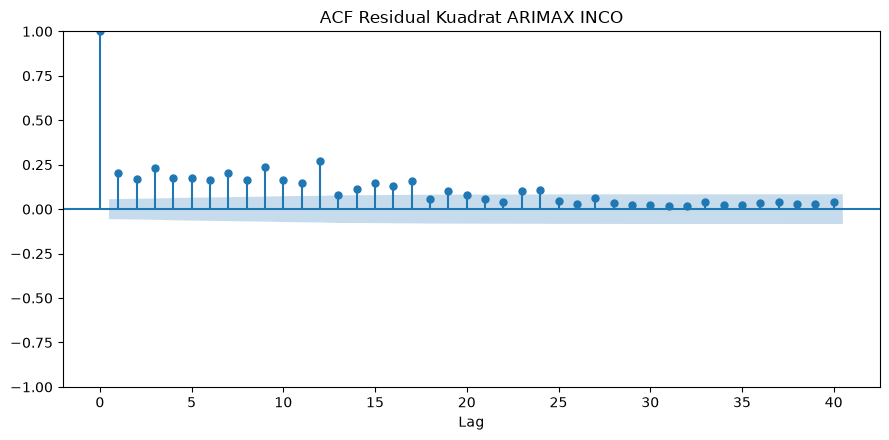

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_acf(residual_arimax["residual_kuadrat"], lags=LAG_ACF, ax=ax, title="ACF Residual Kuadrat ARIMAX " + EMITEN)
ax.set_xlabel("Lag")
plt.tight_layout()
plt.savefig("outputs/gambar_acf_residual_kuadrat_" + EMITEN + ".png", dpi=300)
plt.show()

In [15]:
baris = []
ljung_box = acorr_ljungbox(e, lags=LAG_LJUNG_BOX)
for lag in LAG_LJUNG_BOX:
    p_value = ljung_box.loc[lag, "lb_pvalue"]
    keputusan = "ada autokorelasi" if p_value < ALPHA else "tidak ada autokorelasi"
    baris.append([lag, ljung_box.loc[lag, "lb_stat"], p_value, keputusan])
uji_ljung_box_arimax = pd.DataFrame(baris, columns=["lag", "statistik", "p_value", "keputusan"])
tabel["uji_ljung_box_arimax"] = uji_ljung_box_arimax
display(uji_ljung_box_arimax)

baris = []
for lag in LAG_ARCH:
    lm, p_value, _, _ = het_arch(e, nlags=lag)
    keputusan = "ada efek ARCH" if p_value < ALPHA else "tidak ada efek ARCH"
    baris.append([lag, lm, p_value, keputusan])
uji_arch_lm = pd.DataFrame(baris, columns=["lag", "statistik_lm", "p_value", "keputusan"])
tabel["uji_arch_lm"] = uji_arch_lm
display(uji_arch_lm)

,lag,statistik,p_value,keputusan
0,10,13.121407,0.216963,tidak ada autokorelasi
1,20,26.782696,0.141489,tidak ada autokorelasi


,lag,statistik_lm,p_value,keputusan
0,1,50.837560,1.003352e-12,ada efek ARCH
1,10,171.976271,1.080950e-31,ada efek ARCH
2,12,196.891170,1.428301e-35,ada efek ARCH
3,20,212.630077,3.512092e-34,ada efek ARCH


**Verifikasi manual** $LM = T \cdot R^2 \sim \chi^2_q$. Residual kuadrat $e_t^2$ diregresikan
(OLS) pada konstanta dan $q$ lag-nya:

$$e_t^2 = a_0 + a_1 e_{t-1}^2 + \dots + a_q e_{t-q}^2 + u_t$$

$T$ adalah jumlah observasi regresi ($n - q$) dan $R^2$ berasal dari regresi tersebut. Nilai
LM di bawah harus sama dengan kolom `statistik_lm` di atas.

In [16]:
e2 = e ** 2
baris = []
for lag in LAG_ARCH:
    y = e2[lag:]
    kolom_lag = []
    for j in range(1, lag + 1):
        kolom_lag.append(e2[lag - j:len(e2) - j])
    X = sm.add_constant(np.column_stack(kolom_lag))
    r2 = sm.OLS(y, X).fit().rsquared
    T = len(y)
    lm = T * r2
    chi2_tabel = stats.chi2.ppf(1 - ALPHA, lag)
    p_value = stats.chi2.sf(lm, lag)
    baris.append([lag, T, r2, lm, chi2_tabel, p_value])
lm_manual = pd.DataFrame(baris, columns=["lag", "T", "R2", "LM", "chi2_tabel", "p_value"])
tabel["lm_manual"] = lm_manual
display(lm_manual)

,lag,T,R2,LM,chi2_tabel,p_value
0,1,1215,0.041842,50.837560,3.841459,1.003352e-12
1,10,1206,0.142601,171.976271,18.307038,1.080950e-31
2,12,1204,0.163531,196.891170,21.026070,1.428301e-35
3,20,1196,0.177784,212.630077,31.410433,3.512092e-34


## 8. Uji normalitas residual

Jarque-Bera dan Shapiro-Wilk pada residual ARIMAX $e_t$. $H_0$: residual berdistribusi
normal. Kurtosis yang dilaporkan adalah kurtosis Pearson (distribusi normal = 3).

Distribusi inovasi GARCH ditentukan oleh Jarque-Bera: p-value $\ge$ 0,05 berarti Normal,
selain itu Student-t.

In [17]:
jb = stats.jarque_bera(e)
sw = stats.shapiro(e)
skewness = stats.skew(e)
kurtosis = stats.kurtosis(e, fisher=False)
DIST = "normal" if jb.pvalue >= ALPHA else "t"

uji_normalitas = pd.DataFrame([
    ["Jarque-Bera", jb.statistic, jb.pvalue, "normal" if jb.pvalue >= ALPHA else "tidak normal"],
    ["Shapiro-Wilk", sw.statistic, sw.pvalue, "normal" if sw.pvalue >= ALPHA else "tidak normal"],
    ["Skewness", skewness, np.nan, ""],
    ["Kurtosis", kurtosis, np.nan, ""],
    ["Distribusi terpilih", np.nan, np.nan, "Normal" if DIST == "normal" else "Student-t"],
], columns=["uji", "statistik", "p_value", "keputusan"])
tabel["uji_normalitas"] = uji_normalitas
display(uji_normalitas)

,uji,statistik,p_value,keputusan
0,Jarque-Bera,683.341586,4.113960e-149,tidak normal
1,Shapiro-Wilk,0.944479,5.813294e-21,tidak normal
2,Skewness,0.615104,NaN,
3,Kurtosis,6.460288,NaN,
4,Distribusi terpilih,NaN,NaN,Student-t


## 9. Grid search orde GARCH

Karena persamaan mean sudah dimodelkan oleh ARIMAX, GARCH dipasang langsung pada residual
ARIMAX dengan **persamaan mean nol** (`mean="Zero"`):

$$e_t = \sigma_t z_t, \qquad \sigma_t^2 = \omega + \sum_{i=1}^{p} \alpha_i e_{t-i}^2 + \sum_{j=1}^{q} \beta_j \sigma_{t-j}^2$$

Seluruh kombinasi $p = 1..3$ dan $q = 1..3$ dengan distribusi hasil langkah 8. $p$ adalah
jumlah suku $\alpha$ dan $q$ jumlah suku $\beta$. Parameter diestimasi dengan *Maximum
Likelihood Estimation* pada 1.216 residual training. Orde dipilih dari AIC terkecil.
Verifikasi manual: $AIC = -2\ln(\hat{L}) + 2k$, dengan $k$ jumlah parameter yang diestimasi.

In [18]:
baris = []
hasil_grid = {}
for p_garch in [1, 2, 3]:
    for q_garch in [1, 2, 3]:
        model = arch_model(e, mean="Zero", vol="GARCH", p=p_garch, q=q_garch, dist=DIST, rescale=False)
        hasil_fit = model.fit(disp="off")
        k = len(hasil_fit.params)
        aic_manual = -2 * hasil_fit.loglikelihood + 2 * k
        konvergen = hasil_fit.convergence_flag == 0
        baris.append([p_garch, q_garch, k, hasil_fit.loglikelihood, hasil_fit.aic, aic_manual, hasil_fit.bic, konvergen])
        hasil_grid[(p_garch, q_garch)] = hasil_fit
grid_orde_aic = pd.DataFrame(baris, columns=["p", "q", "k", "log_likelihood", "aic", "aic_manual", "bic", "konvergen"])
tabel["grid_orde_aic"] = grid_orde_aic
display(grid_orde_aic)

,p,q,k,log_likelihood,aic,aic_manual,bic,konvergen
0,1,1,4,-2783.635105,5575.270211,5575.270211,5595.683499,True
1,1,2,5,-2783.635088,5577.270175,5577.270175,5602.786785,True
2,1,3,6,-2783.592753,5579.185507,5579.185507,5609.805439,True
3,2,1,5,-2783.635105,5577.270210,5577.270210,5602.786821,True
4,2,2,6,-2783.601127,5579.202253,5579.202253,5609.822186,True
5,2,3,7,-2783.422517,5580.845033,5580.845033,5616.568288,True
6,3,1,6,-2783.635105,5579.270210,5579.270210,5609.890143,True
7,3,2,7,-2783.601127,5581.202253,5581.202253,5616.925508,True
8,3,3,8,-2783.424848,5582.849697,5582.849697,5623.676273,True


In [19]:
baris_terpilih = grid_orde_aic.loc[grid_orde_aic["aic"].idxmin()]   # AIC terkecil
P = int(baris_terpilih["p"])
Q = int(baris_terpilih["q"])
hasil = hasil_grid[(P, Q)]
assert hasil.convergence_flag == 0
print("orde terpilih: p =", P, ", q =", Q, ", distribusi:", DIST)

orde terpilih: p = 1 , q = 1 , distribusi: t


In [20]:
# ringkasan lengkap model GARCH terpilih (AIC terkecil), untuk transparansi hasil
print(hasil.summary())

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                            y   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.001
Vol Model:                            GARCH   Log-Likelihood:               -2783.64
Distribution:      Standardized Student's t   AIC:                           5575.27
Method:                  Maximum Likelihood   BIC:                           5595.68
                                              No. Observations:                 1216
Date:                      Mon, Oct 05 2026   Df Residuals:                     1216
Time:                              17:23:54   Df Model:                            0
                              Volatility Model                             
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega  

## 10. Estimasi parameter dan persamaan GARCH

Estimasi ini adalah satu-satunya estimasi GARCH. Parameter yang sama dipakai untuk
menghasilkan kolom `garch_vol` (langkah 12). Standard error memakai kovarians robust (bawaan
library `arch`). Tidak ada parameter $\mu$ karena persamaan mean bernilai nol.

In [21]:
parameter_garch = pd.DataFrame({
    "parameter": hasil.params.index,
    "koefisien": hasil.params.values,
    "std_error": hasil.std_err.values,
    "t_statistik": hasil.tvalues.values,
    "p_value": hasil.pvalues.values,
})
tabel["parameter_garch"] = parameter_garch
display(parameter_garch)

,parameter,koefisien,std_error,t_statistik,p_value
0,omega,0.094295,0.052117,1.809287,7.040648e-02
1,alpha[1],0.094497,0.023750,3.978768,6.927332e-05
2,beta[1],0.901708,0.023599,38.209324,0.000000e+00
3,nu,4.711377,0.589291,7.994993,1.295815e-15


In [22]:
omega = hasil.params["omega"]
alpha = [hasil.params["alpha[" + str(i) + "]"] for i in range(1, P + 1)]
beta = [hasil.params["beta[" + str(j) + "]"] for j in range(1, Q + 1)]

persamaan_varians = "sigma^2_t = " + f"{omega:.6f}"
for i in range(1, P + 1):
    persamaan_varians += " + " + f"{alpha[i - 1]:.6f}" + " e^2_(t-" + str(i) + ")"
for j in range(1, Q + 1):
    persamaan_varians += " + " + f"{beta[j - 1]:.6f}" + " sigma^2_(t-" + str(j) + ")"

persamaan_garch = pd.DataFrame({"persamaan": ["mean", "varians"],
                                "rumus": ["e_t = sigma_t z_t  (e_t = residual ARIMAX, mean nol)", persamaan_varians]})
tabel["persamaan_garch"] = persamaan_garch
display(persamaan_garch)

,persamaan,rumus
0,mean,"e_t = sigma_t z_t (e_t = residual ARIMAX, mean nol)"
1,varians,sigma^2_t = 0.094295 + 0.094497 e^2_(t-1) + 0.901708 sigma^2_(t-1)


## 11. Diagnostik residual terstandarisasi

Residual terstandarisasi $z_t = \hat{e}_t / \hat{\sigma}_t$. Uji Ljung-Box lag 10 dan 20
($H_0$: tidak ada autokorelasi) dan uji ARCH-LM lag 1, 10, 12, 20 ($H_0$: tidak ada efek
ARCH tersisa), taraf signifikansi 5%.

In [23]:
z = hasil.std_resid
baris = []
ljung_box = acorr_ljungbox(z, lags=LAG_LJUNG_BOX)
for lag in LAG_LJUNG_BOX:
    statistik = ljung_box.loc[lag, "lb_stat"]
    p_value = ljung_box.loc[lag, "lb_pvalue"]
    keputusan = "ada autokorelasi" if p_value < ALPHA else "tidak ada autokorelasi"
    baris.append(["Ljung-Box", lag, statistik, p_value, keputusan])
for lag in LAG_ARCH:
    lm, p_value, _, _ = het_arch(z, nlags=lag)
    keputusan = "ada efek ARCH" if p_value < ALPHA else "tidak ada efek ARCH"
    baris.append(["ARCH-LM", lag, lm, p_value, keputusan])
diagnostik_residual = pd.DataFrame(baris, columns=["uji", "lag", "statistik", "p_value", "keputusan"])
tabel["diagnostik_residual"] = diagnostik_residual
display(diagnostik_residual)

,uji,lag,statistik,p_value,keputusan
0,Ljung-Box,10,9.756481,0.462112,tidak ada autokorelasi
1,Ljung-Box,20,17.068434,0.648526,tidak ada autokorelasi
2,ARCH-LM,1,0.002987,0.956414,tidak ada efek ARCH
3,ARCH-LM,10,5.179805,0.878848,tidak ada efek ARCH
4,ARCH-LM,12,7.183205,0.845273,tidak ada efek ARCH
5,ARCH-LM,20,15.982834,0.717689,tidak ada efek ARCH


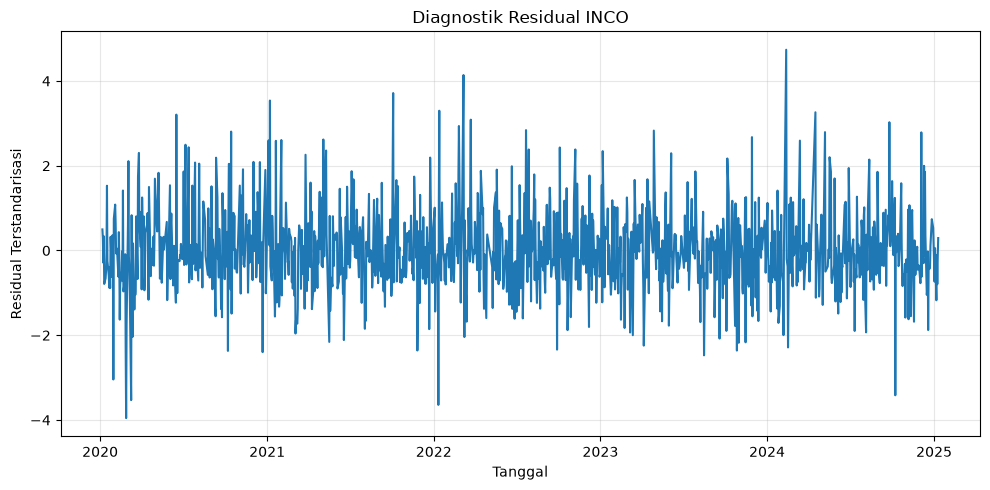

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train["Tanggal"], z, color="tab:blue")
ax.set_title("Diagnostik Residual " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Residual Terstandarisasi")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/gambar_diagnostik_residual_" + EMITEN + ".png", dpi=300)
plt.show()

## 12. Volatilitas kondisional

1. **Residual ARIMAX seluruh periode.** Parameter ARIMAX dibekukan, lalu model dijalankan pada
   seluruh 1.521 hari (`apply`, tanpa fitting ulang). Pada periode training hasilnya sama
   dengan residual model; pada periode testing residualnya adalah log return aktual dikurangi
   ramalan satu langkah, $e_t = r_t - \hat{r}_t$.
2. **Volatilitas.** Periode training memakai volatilitas kondisional *in-sample* dari model
   GARCH. Periode testing memakai rekursi satu langkah dengan parameter dibekukan:

$$\sigma_t^2 = \omega + \sum_{i=1}^{p} \alpha_i e_{t-i}^2 + \sum_{j=1}^{q} \beta_j \sigma_{t-j}^2$$

$\sigma_t$ hanya memakai residual dan varians sampai hari $t-1$, sehingga tidak ada
*look-ahead* pada periode testing.

**Nilai awal (backcast).** Pada hari pertama sampel, suku lag diisi *backcast* library
`arch`. Karena mean bernilai nol, residual tidak dikurangi rata-rata:

$$backcast = \sum_{i=0}^{74} w_i\, e_{i+1}^2, \qquad w_i = \frac{0{,}94^i}{\sum_{j=0}^{74} 0{,}94^j}$$

Rekursi manual dijalankan dari hari pertama sampel (6 Januari 2020) sampai 30 April 2026.
Pada periode training, hasilnya diverifikasi harus sama dengan keluaran model.

In [25]:
# residual ARIMAX seluruh periode: parameter training dibekukan, model dijalankan tanpa fitting ulang
hasil_penuh = hasil_arimax.apply(sampel[KOLOM_Y].values, exog=sampel[KOLOM_X].values)
r_ramalan = np.asarray(hasil_penuh.fittedvalues)   # ramalan satu langkah setiap hari
eps = np.asarray(hasil_penuh.resid)
assert np.allclose(eps[:n_train], e)                              # periode training = residual model
assert np.allclose(eps, sampel[KOLOM_Y].values - r_ramalan)       # residual = aktual - ramalan

bobot = 0.94 ** np.arange(75)
bobot = bobot / bobot.sum()
backcast = np.sum(bobot * e[:75] ** 2)

sigma2 = np.zeros(N)
for t in range(N):
    sigma2[t] = omega
    for i in range(1, P + 1):
        if t - i >= 0:
            sigma2[t] += alpha[i - 1] * eps[t - i] ** 2
        else:
            sigma2[t] += alpha[i - 1] * backcast
    for j in range(1, Q + 1):
        if t - j >= 0:
            sigma2[t] += beta[j - 1] * sigma2[t - j]
        else:
            sigma2[t] += beta[j - 1] * backcast
sigma_manual = np.sqrt(sigma2)

# verifikasi: pada periode training, rekursi manual sama dengan keluaran model
assert np.allclose(sigma_manual[:n_train], hasil.conditional_volatility)

# training: keluaran model (in-sample), testing: rekursi dengan parameter dibekukan
sigma = np.concatenate([hasil.conditional_volatility, sigma_manual[n_train:]])

**Contoh perhitungan manual $\sigma_t$ per suku** untuk hari pertama sampel (6 Januari 2020,
suku lag diisi backcast) dan hari testing pertama (13 Januari 2025). Kolom `hari_ke` adalah
urutan hari pada sampel 1.521 hari. Baris `sigma_t model` adalah pembanding dari library
`arch`: *conditional volatility* untuk hari pertama, dan *forecast* satu langkah dari akhir
data training untuk hari testing pertama.

In [26]:
sigma_model_test = np.sqrt(hasil.forecast(horizon=1, reindex=False).variance.values[-1, 0])
contoh = [
    (0, hasil.conditional_volatility[0], "conditional volatility arch"),
    (n_train, sigma_model_test, "forecast satu langkah arch"),
]

baris = []
for t, sigma_model, sumber_model in contoh:
    tgl = sampel["Tanggal"][t]
    total = omega
    baris.append([tgl, t + 1, "omega", omega, np.nan, "", omega])
    for i in range(1, P + 1):
        if t - i >= 0:
            nilai = eps[t - i] ** 2
            keterangan = "e^2 hari ke-" + str(t - i + 1)
        else:
            nilai = backcast
            keterangan = "backcast"
        baris.append([tgl, t + 1, "alpha[" + str(i) + "] x e^2_(t-" + str(i) + ")", alpha[i - 1], nilai, keterangan, alpha[i - 1] * nilai])
        total += alpha[i - 1] * nilai
    for j in range(1, Q + 1):
        if t - j >= 0:
            nilai = sigma2[t - j]
            keterangan = "sigma^2 hari ke-" + str(t - j + 1)
        else:
            nilai = backcast
            keterangan = "backcast"
        baris.append([tgl, t + 1, "beta[" + str(j) + "] x sigma^2_(t-" + str(j) + ")", beta[j - 1], nilai, keterangan, beta[j - 1] * nilai])
        total += beta[j - 1] * nilai
    baris.append([tgl, t + 1, "sigma^2_t", np.nan, np.nan, "jumlah suku", total])
    baris.append([tgl, t + 1, "sigma_t manual", np.nan, np.nan, "akar sigma^2_t", np.sqrt(total)])
    baris.append([tgl, t + 1, "sigma_t model", np.nan, np.nan, sumber_model, sigma_model])

contoh_hitung_sigma = pd.DataFrame(baris, columns=["Tanggal", "hari_ke", "suku", "koefisien", "nilai", "keterangan", "hasil"])
tabel["contoh_hitung_sigma"] = contoh_hitung_sigma
display(contoh_hitung_sigma)

,Tanggal,hari_ke,suku,koefisien,nilai,keterangan,hasil
0,2020-01-06,1,omega,0.094295,NaN,,0.094295
1,2020-01-06,1,alpha[1] x e^2_(t-1),0.094497,6.567903,backcast,0.620650
2,2020-01-06,1,beta[1] x sigma^2_(t-1),0.901708,6.567903,backcast,5.922328
3,2020-01-06,1,sigma^2_t,NaN,NaN,jumlah suku,6.637273
4,2020-01-06,1,sigma_t manual,NaN,NaN,akar sigma^2_t,2.576291
5,2020-01-06,1,sigma_t model,NaN,NaN,conditional volatility arch,2.576291
6,2025-01-13,1217,omega,0.094295,NaN,,0.094295
7,2025-01-13,1217,alpha[1] x e^2_(t-1),0.094497,0.310833,e^2 hari ke-1216,0.029373
8,2025-01-13,1217,beta[1] x sigma^2_(t-1),0.901708,3.611184,sigma^2 hari ke-1216,3.256232
9,2025-01-13,1217,sigma^2_t,NaN,NaN,jumlah suku,3.379900


Tabel volatilitas kondisional 1.521 hari. Kolom `residual` adalah residual ARIMAX (training:
residual model, testing: aktual dikurangi ramalan satu langkah). Kolom `sigma` menjadi fitur
`garch_vol`.

In [27]:
conditional_volatility = pd.DataFrame({
    "Tanggal": sampel["Tanggal"],
    "log_return": sampel[KOLOM_Y],
    "residual": eps,
    "sigma": sigma,
    "periode": sampel["periode"],
})
tabel["conditional_volatility"] = conditional_volatility
tampil(conditional_volatility)

,Tanggal,log_return,residual,sigma,periode
0,2020-01-06,0.853490,1.280675,2.576291,training
1,2020-01-07,0.846267,0.733561,2.496830,training
2,2020-01-08,-0.563382,-0.694190,2.401361,training
3,2020-01-09,0.843887,0.777390,2.310750,training
4,2020-01-10,-1.694956,-1.759011,2.228481,training
5,2020-01-13,-1.434745,-1.444501,2.205601,training
6,2020-01-14,-1.162804,-1.018968,2.162866,training
7,2020-01-15,-0.292826,-0.056850,2.100140,training
8,2020-01-16,3.458558,3.082799,2.017836,training
9,2020-01-17,-0.853490,-0.530893,2.159587,training


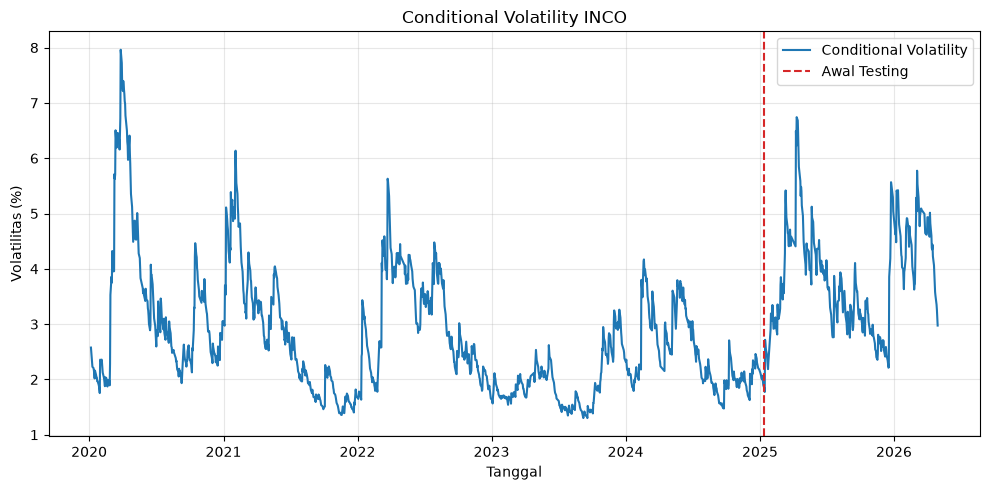

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(conditional_volatility["Tanggal"], conditional_volatility["sigma"], color="tab:blue", label="Conditional Volatility")
ax.axvline(sampel["Tanggal"][n_train], color="tab:red", ls="--", lw=1.5, label="Awal Testing")
ax.set_title("Conditional Volatility " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Volatilitas (%)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("outputs/gambar_conditional_volatility_" + EMITEN + ".png", dpi=300)
plt.show()

## 13. Peramalan ARIMAX-GARCH pada data testing

Setiap hari testing diramal satu langkah ke depan dengan parameter yang dibekukan. Ramalan
log return berasal dari persamaan mean ARIMAX ($\hat{r}_t$, memakai log return saham sampai
hari $t-1$ dan eksogen hari $t-1$), lalu dikembalikan ke harga dengan harga aktual kemarin:

$$\hat{P}_t = P_{t-1} \times \exp\left(\frac{\hat{r}_t}{100}\right)$$

GARCH tidak mengubah titik ramalan. GARCH memberi ramalan volatilitas $\sigma_t$ untuk hari
yang sama (kolom `sigma`, dalam persen log return), sehingga titik ramalan ARIMAX-GARCH sama
dengan ramalan persamaan mean ARIMAX.

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2} \qquad MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad MAPE = \frac{1}{n}\sum_{i=1}^{n}\left|\frac{y_i - \hat{y}_i}{y_i}\right| \times 100\%$$

dengan $n = 305$, pada skala harga asli (Rupiah). Kolom `selisih` = aktual - prediksi, dan
`error_persen` = |selisih / aktual| x 100.

In [29]:
r_prediksi = np.asarray(hasil_penuh.predict(start=n_train, end=N - 1))
assert np.allclose(r_prediksi, r_ramalan[n_train:])

harga_kemarin = sampel[KOLOM].values[n_train - 1:N - 1]
aktual = sampel[KOLOM].values[n_train:]
prediksi = harga_kemarin * np.exp(r_prediksi / 100)
assert len(prediksi) == 305

prediksi_arimax_garch = pd.DataFrame({
    "Tanggal": sampel["Tanggal"].values[n_train:],
    "log_return_aktual": sampel[KOLOM_Y].values[n_train:],
    "log_return_prediksi": r_prediksi,
    "sigma": sigma[n_train:],
    "harga_kemarin": harga_kemarin,
    "aktual": aktual,
    "prediksi": prediksi,
})
prediksi_arimax_garch["selisih"] = prediksi_arimax_garch["aktual"] - prediksi_arimax_garch["prediksi"]
prediksi_arimax_garch["error_persen"] = (prediksi_arimax_garch["selisih"] / prediksi_arimax_garch["aktual"]).abs() * 100
tabel["prediksi_arimax_garch"] = prediksi_arimax_garch
tampil(prediksi_arimax_garch)

rmse = np.sqrt(np.mean((aktual - prediksi) ** 2))
mae = np.mean(np.abs(aktual - prediksi))
mape = np.mean(np.abs((aktual - prediksi) / aktual)) * 100
metrik = pd.DataFrame([[rmse, mae, mape]], columns=["rmse", "mae", "mape"])
tabel["metrik"] = metrik
display(metrik)

,Tanggal,log_return_aktual,log_return_prediksi,sigma,harga_kemarin,aktual,prediksi,selisih,error_persen
0,2025-01-13,0.000000,0.141436,1.838450,3430.0,3430.0,3434.854682,-4.854682,0.141536
1,2025-01-14,7.035249,0.172147,1.773095,3430.0,3680.0,3435.909713,244.090287,6.632888
2,2025-01-15,-0.818558,0.346291,2.716649,3680.0,3650.0,3692.765581,-42.765581,1.171660
3,2025-01-16,-1.657497,-0.140010,2.622457,3650.0,3590.0,3644.893199,-54.893199,1.529058
4,2025-01-17,-0.558661,0.020703,2.552097,3590.0,3570.0,3590.743327,-20.743327,0.581046
5,2025-01-20,0.279720,0.069168,2.449288,3570.0,3580.0,3572.470143,7.529857,0.210331
6,2025-01-21,0.000000,-0.011337,2.346879,3580.0,3580.0,3579.594142,0.405858,0.011337
7,2025-01-22,-1.123607,0.021207,2.249615,3580.0,3540.0,3580.759287,-40.759287,1.151392
8,2025-01-23,-3.448618,-0.275392,2.186659,3540.0,3420.0,3530.264548,-110.264548,3.224110
9,2025-01-24,-6.336961,-0.227280,2.314588,3420.0,3210.0,3412.235854,-202.235854,6.300182


,rmse,mae,mape
0,175.352506,123.168232,2.886486


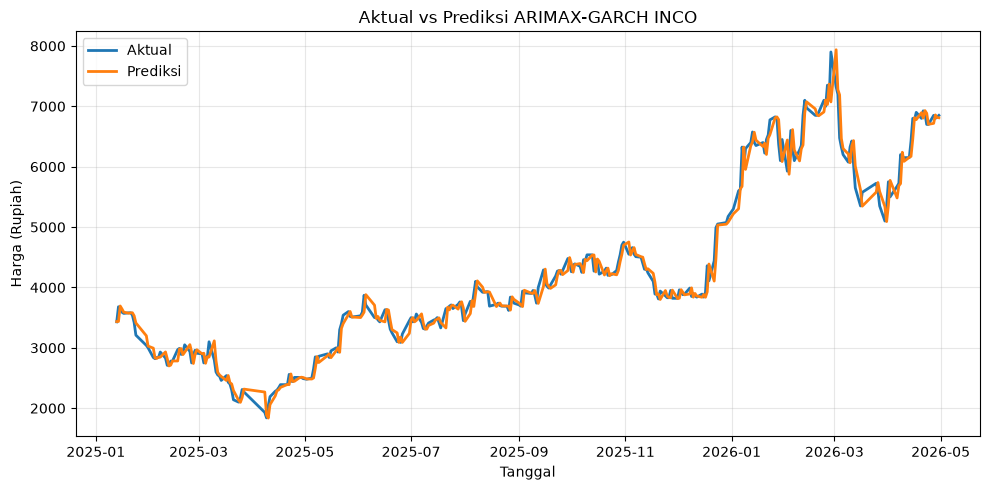

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(prediksi_arimax_garch["Tanggal"], prediksi_arimax_garch["aktual"], color="tab:blue", lw=2, label="Aktual")
ax.plot(prediksi_arimax_garch["Tanggal"], prediksi_arimax_garch["prediksi"], color="tab:orange", lw=2, label="Prediksi")
ax.set_title("Aktual vs Prediksi ARIMAX-GARCH " + EMITEN)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga (Rupiah)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("outputs/gambar_prediksi_ARIMAX-GARCH_" + EMITEN + ".png", dpi=300)
plt.show()

## 14. Simpan tabel

Seluruh tabel disimpan utuh ke `outputs/01_arimax_garch_{EMITEN}.xlsx`, satu tabel per sheet
sesuai urutan langkah. Persamaan model ada di sheet `persamaan_arimax` dan `persamaan_garch`.

In [31]:
with pd.ExcelWriter(BERKAS_XLSX, date_format="YYYY-MM-DD", datetime_format="YYYY-MM-DD") as writer:
    for nama_sheet in tabel:
        tabel[nama_sheet].to_excel(writer, sheet_name=nama_sheet, index=False)